# Laboratorio 4 — Segmentación de lesiones con K-medias

**Curso:** ISIS2611 — Aprendizaje de Máquina  
**Caso:** DermAlpes  
**Integrantes:** Laura Sanchez y Baruc Bastidas 

## ¿Qué vamos a hacer?

Queremos separar la región de una lesión de la piel del resto de la fotografía. Usaremos **K-medias**, que agrupa píxeles con colores y posiciones parecidas. **El método no diagnostica enfermedades**: solamente propone una región para que la revise una persona especialista.

## 1. Bibliotecas, semilla y protocolo

Fijamos una semilla para poder repetir el experimento. Reducimos cada imagen a **64 × 64 píxeles** para que las 1.050 búsquedas de agrupaciones (15 imágenes × 10 combinaciones × 7 valores de K) sean manejables. Las máscaras siempre se cambian de tamaño con **vecino más cercano**: así conservan valores 0 y 1.

In [15]:
import os, io, zipfile, urllib.request, pathlib, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)
from sklearn.decomposition import PCA
from IPython.display import display

SEED = 2611
SIZE = (64, 64)
N_FIT = 1200        # muestra para ajustar K-medias
N_SIL = 220         # muestra reproducible para calcular silueta
N_INIT = 3
np.random.seed(SEED)
print('Semilla:', SEED, '| imagen:', SIZE, '| muestra silueta:', N_SIL)

Semilla: 2611 | imagen: (64, 64) | muestra silueta: 220


## 2. Conjunto de datos: 15 imágenes de ajuste y 5 de prueba

Se utilizan exactamente los identificadores asignados. Los archivos de imagen tienen nombre `ISIC_xxxxxxx.jpg` y las referencias `ISIC_xxxxxxx_Segmentation.png`. Se pueden poner en la carpeta `datos_isic_2016` junto al notebook. Si no están, el código descarga **los archivos oficiales de entrenamiento de 2016**, una operación que requiere conexión a internet y alrededor de 610 MB de transferencia inicial. Solo extrae las 20 parejas necesarias.

**Fuente:** Gutman, D. et al. (2016). *Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC).* https://challenge.isic-archive.com/landing/2016/37/ . Archivos oficiales: https://isic-challenge-data.s3.amazonaws.com/2016/ .

In [16]:
AJUSTE = ['ISIC_0000085', 'ISIC_0000086', 'ISIC_0000089', 'ISIC_0000094', 'ISIC_0000108',
          'ISIC_0000114', 'ISIC_0000116', 'ISIC_0000122', 'ISIC_0000133', 'ISIC_0000137',
          'ISIC_0000150', 'ISIC_0000153', 'ISIC_0000156', 'ISIC_0000157', 'ISIC_0000112']
PRUEBA = ['ISIC_0000087', 'ISIC_0000105', 'ISIC_0000110', 'ISIC_0000123', 'ISIC_0000128']
assert len(AJUSTE) == 15 and len(PRUEBA) == 5 and not set(AJUSTE) & set(PRUEBA)
IDS = AJUSTE + PRUEBA

# Las imágenes ya están descargadas en estas dos carpetas, junto al notebook.
from pathlib import Path
RUTA_IMAGENES = Path('datos/imagenes')
RUTA_MASCARAS = Path('datos/mascaras')

def preparar_datos():
    faltantes = []
    for nombre in IDS:
        imagen = RUTA_IMAGENES / f'{nombre}.jpg'
        mascara = RUTA_MASCARAS / f'{nombre}_Segmentation.png'
        if not imagen.is_file():
            faltantes.append(str(imagen))
        if not mascara.is_file():
            faltantes.append(str(mascara))
    if faltantes:
        raise FileNotFoundError('No se encontraron estos archivos:\n' + '\n'.join(faltantes))
    print('¡Datos preparados correctamente!')
    print('Imágenes de ajuste:', len(AJUSTE))
    print('Imágenes de prueba:', len(PRUEBA))
    print('Total de imágenes:', len(IDS))

preparar_datos()

¡Datos preparados correctamente!
Imágenes de ajuste: 15
Imágenes de prueba: 5
Total de imágenes: 20


### Organización del conjunto de datos

Para este laboratorio utilizamos 20 imágenes del conjunto de datos ISIC 2016, cada una con su respectiva máscara de referencia. Las imágenes se encuentran guardadas en la carpeta `datos/imagenes` y las máscaras en `datos/mascaras`.

De las 20 imágenes, utilizamos 15 para ajustar el método y seleccionar la mejor configuración, mientras que las otras 5 se reservaron para evaluar su funcionamiento.

Esta separación es importante porque permite comprobar cómo funciona el método con imágenes que no se utilizaron para elegir los parámetros. De esta manera, obtenemos una evaluación más confiable.

Las imágenes originales están en formato JPG y las máscaras en formato PNG. Las máscaras indican con el valor 1 los píxeles que pertenecen a la lesión y con el valor 0 los que corresponden a la piel o al fondo.

## 3. Preparación de imágenes y máscaras

Leemos el color en RGB y lo normalizamos a [0, 1]. En las máscaras: **0 significa piel/fondo** y **1 significa lesión**. Comprobamos que la imagen y la máscara tienen el mismo tamaño.

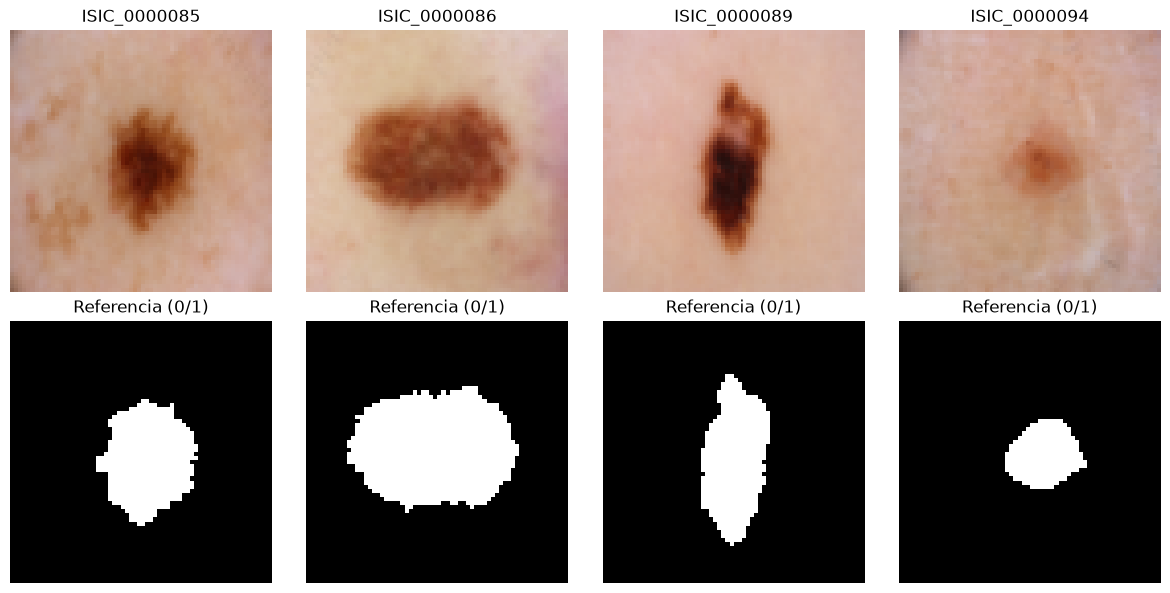

In [17]:
def cargar_par(ident):
    imagen=np.asarray(Image.open(RUTA_IMAGENES/f'{ident}.jpg').convert('RGB').resize(SIZE, Image.Resampling.BILINEAR),dtype=np.float32)/255.0
    mascara=np.asarray(Image.open(RUTA_MASCARAS/f'{ident}_Segmentation.png').convert('L').resize(SIZE,Image.Resampling.NEAREST))
    mascara=(mascara>127).astype(np.uint8)
    assert imagen.shape[:2]==mascara.shape and set(np.unique(mascara)).issubset({0,1})
    return imagen,mascara

DATOS={i:cargar_par(i) for i in IDS}
fig,ax=plt.subplots(2,4,figsize=(12,6))
for j,i in enumerate(AJUSTE[:4]):
    img,mask=DATOS[i]; ax[0,j].imshow(img);ax[0,j].set_title(i)
    ax[1,j].imshow(mask,cmap='gray',vmin=0,vmax=1);ax[1,j].set_title('Referencia (0/1)')
for a in ax.ravel():a.axis('off')
plt.tight_layout();plt.show()

## 4. Pipeline de Scikit-learn: cinco características por píxel

A cada píxel le damos cinco números: **[β·R, β·G, β·B, λ·x, λ·y]**. β controla la importancia del color y λ la de la ubicación. Los colores y las coordenadas se normalizan a [0, 1] **antes** de aplicar los pesos. Esto permite cambiar β y λ sin modificar el código.

In [18]:
class PixelFeatures(BaseEstimator,TransformerMixin):
    def __init__(self,beta=1.0,lam=0.3):
        self.beta=beta;self.lam=lam
    def fit(self,X,y=None): return self
    def transform(self,X):
        X=np.asarray(X,dtype=np.float32)
        h,w,_=X.shape
        rgb=X.reshape(-1,3)
        if rgb.max()>1:rgb=rgb/255.0
        yy,xx=np.mgrid[0:h,0:w]
        pos=np.column_stack((xx.ravel()/max(w-1,1),yy.ravel()/max(h-1,1))).astype(np.float32)
        return np.column_stack((self.beta*rgb,self.lam*pos)).astype(np.float32)

def pipeline(beta,lam):return Pipeline([('caracteristicas',PixelFeatures(beta,lam))])

prueba_x=pipeline(1,0.3).fit_transform(DATOS[AJUSTE[0]][0])
assert prueba_x.shape==(SIZE[0]*SIZE[1],5)
print('Forma de representación:',prueba_x.shape)

Forma de representación: (4096, 5)


## 5. Las diez combinaciones y la selección de K

Solo importa la **relación** λ/β. Por eso fijamos β=1 cuando usamos color y variamos λ. Probamos también solo color y solo posición. Para cada imagen y combinación, ajustamos K-medias para **K=2,3,...,8**. Elegimos el K con **mayor coeficiente de silueta** (una medida de qué tan separados están los grupos), calculado sobre una muestra fija y reproducible de **220 píxeles**. **No miramos las máscaras de referencia para elegir K**.

In [19]:
CONFIGS=[(1.,0.),(1.,.05),(1.,.10),(1.,.20),(1.,.35),
         (1.,.50),(1.,.75),(1.,1.),(1.,2.),(0.,1.)]
assert len(CONFIGS)==10

def nombre_cfg(beta,lam):return f'b={beta:g}, l={lam:g}'

def agrupar(img,beta,lam,ident,k_fijo=None):
    X=pipeline(beta,lam).fit_transform(img)
    rng=np.random.default_rng(SEED+IDS.index(ident))
    orden=rng.permutation(len(X))
    fit_idx=orden[:min(N_FIT,len(X))]
    sil_idx=orden[:min(N_SIL,len(X))]
    ks=[k_fijo] if k_fijo is not None else range(2,9)
    resultados=[]
    for k in ks:
        modelo=KMeans(n_clusters=k,random_state=SEED,n_init=N_INIT,max_iter=100)
        modelo.fit(X[fit_idx])
        muestra=modelo.predict(X[sil_idx])
        sil=(silhouette_score(X[sil_idx],muestra)
             if len(np.unique(muestra))>1 else -1.)
        resultados.append((sil,k,modelo))
    sil,k,modelo=max(resultados,key=lambda t:(t[0],-t[1]))
    labels=modelo.predict(X).reshape(img.shape[:2])
    return {'labels':labels,'K':k,'silueta':float(sil)}

## 6. De los grupos a una máscara binaria

K-medias no sabe cuál grupo es la lesión. Probamos **dos reglas automáticas**, sin consultar las máscaras correctas de cada foto:

- **`oscuro`**: marcamos los grupos cuya luminosidad media es claramente menor que la del grupo más claro. Como muchas lesiones se ven oscuras, es una primera aproximación. Puede fallar con sombras o lesiones claras.
- **`oscuro_centro`**: seleccionamos el grupo oscuro más cercano a la zona central, evitando en lo posible regiones que cubran los bordes. Busca disminuir los falsos positivos de fondos oscuros. Puede fallar si la lesión está descentrada.

Estos criterios son hipótesis, no verdades médicas. Los validamos **solo con las 15 imágenes de ajuste**.

In [20]:
def mascara_desde_grupos(img,labels,criterio):
    h,w=labels.shape
    ys,xs=np.mgrid[0:h,0:w]
    grupos=np.unique(labels)
    infos=[]
    for g in grupos:
        m=labels==g
        luminosidad=float(np.mean(img[m] @ np.array([.2126,.7152,.0722])))
        cy=float(np.mean(ys[m]/max(h-1,1)));cx=float(np.mean(xs[m]/max(w-1,1)))
        borde=float(np.mean(np.r_[m[0],m[-1],m[:,0],m[:,-1]]))
        infos.append((int(g),luminosidad,np.hypot(cx-.5,cy-.5),borde,float(m.mean())))
    # Opción 1: el grupo con brillo promedio mínimo.
    if criterio=='oscuro':
        elegidos=[min(infos,key=lambda t:t[1])[0]]
    elif criterio=='oscuro_centro':
        # Es una regla general fija: combinar brillo, centro y porcentaje del borde.
        # La puntuación es menor cuando el grupo se ve oscuro, central y poco periférico.
        elegidos=[min(infos,key=lambda t:t[1]+0.35*t[2]+0.25*t[3])[0]]
    else:raise ValueError('Criterio no reconocido')
    return np.isin(labels,elegidos).astype(np.uint8)

def metricas(mask_ref,mask_hat,labels):
    verdad=mask_ref.ravel();estimada=mask_hat.ravel()
    return {'Dice':f1_score(verdad,estimada,zero_division=0),
            'V_measure':v_measure_score(verdad,labels.ravel()),
            'precision':precision_score(verdad,estimada,zero_division=0),
            'recall':recall_score(verdad,estimada,zero_division=0)}

## 7. Ajuste completo de las 15 imágenes (SIN tocar prueba)

Para cada combinación calculamos K por silueta y evaluamos **dos criterios** de máscara. Para elegir la configuración final nos importa sobre todo el **Dice promedio**; V-measure es una comparación complementaria de grupos. Conservamos resultados individuales para analizar dónde falla.

In [21]:
filas=[]; CACHE_AJUSTE={}; inicio=time.time()
for i,ident in enumerate(AJUSTE,1):
    img,ref=DATOS[ident]
    for beta,lam in CONFIGS:
        res=agrupar(img,beta,lam,ident)
        CACHE_AJUSTE[(ident,beta,lam)]=res
        for criterio in ('oscuro','oscuro_centro'):
            pred=mascara_desde_grupos(img,res['labels'],criterio)
            filas.append({'imagen':ident,'beta':beta,'lambda':lam,'config':nombre_cfg(beta,lam),
                          'criterio':criterio,'K':res['K'],'silueta':res['silueta'],
                          **metricas(ref,pred,res['labels'])})
    print(f'Ajuste: {i}/{len(AJUSTE)} completadas; tiempo {time.time()-inicio:.1f}s')
df_ajuste=pd.DataFrame(filas)
resumen=(df_ajuste.groupby(['beta','lambda','config','criterio'],as_index=False)
         .agg(Dice_promedio=('Dice','mean'),V_promedio=('V_measure','mean'),
              silueta_promedio=('silueta','mean'),Dice_minimo=('Dice','min'))
         .sort_values(['Dice_promedio','V_promedio'],ascending=False).reset_index(drop=True))
display(resumen.round(3))
print('Total evaluado:',len(df_ajuste),'filas = 15 imágenes × 10 combinaciones × 2 criterios')
assert len(df_ajuste)==300

Ajuste: 1/15 completadas; tiempo 0.5s
Ajuste: 2/15 completadas; tiempo 0.9s
Ajuste: 3/15 completadas; tiempo 1.3s
Ajuste: 4/15 completadas; tiempo 1.8s
Ajuste: 5/15 completadas; tiempo 2.1s
Ajuste: 6/15 completadas; tiempo 2.5s
Ajuste: 7/15 completadas; tiempo 3.0s
Ajuste: 8/15 completadas; tiempo 3.4s
Ajuste: 9/15 completadas; tiempo 3.8s
Ajuste: 10/15 completadas; tiempo 4.3s
Ajuste: 11/15 completadas; tiempo 4.7s
Ajuste: 12/15 completadas; tiempo 5.1s
Ajuste: 13/15 completadas; tiempo 5.5s
Ajuste: 14/15 completadas; tiempo 5.9s
Ajuste: 15/15 completadas; tiempo 6.3s


,beta,lambda,config,criterio,Dice_promedio,V_promedio,silueta_promedio,Dice_minimo
0,1.0,0.50,"b=1, l=0.5",oscuro,0.867,0.540,0.486,0.745
1,1.0,0.50,"b=1, l=0.5",oscuro_centro,0.867,0.540,0.486,0.745
2,1.0,0.75,"b=1, l=0.75",oscuro,0.860,0.372,0.443,0.735
3,1.0,0.75,"b=1, l=0.75",oscuro_centro,0.860,0.372,0.443,0.735
4,1.0,0.20,"b=1, l=0.2",oscuro,0.859,0.632,0.639,0.596
5,1.0,0.20,"b=1, l=0.2",oscuro_centro,0.859,0.632,0.639,0.596
6,1.0,0.05,"b=1, l=0.05",oscuro,0.856,0.659,0.739,0.595
7,1.0,0.05,"b=1, l=0.05",oscuro_centro,0.856,0.659,0.739,0.595
8,1.0,0.10,"b=1, l=0.1",oscuro,0.856,0.659,0.716,0.595
9,1.0,0.10,"b=1, l=0.1",oscuro_centro,0.856,0.659,0.716,0.595


Total evaluado: 300 filas = 15 imágenes × 10 combinaciones × 2 criterios


## 8. Selección de configuración y comparación visual

**Regla de elección fijada antes de revisar prueba:** seleccionar la configuración con el **mayor Dice promedio en ajuste**; en un empate usar V-measure promedio. Se muestran las dos configuraciones ganadoras y los extremos de solo color y solo posición.

CONFIGURACIÓN FINAL CONGELADA
beta: 1.0 lambda: 0.5 criterio: oscuro
Dice medio en ajuste: 0.867


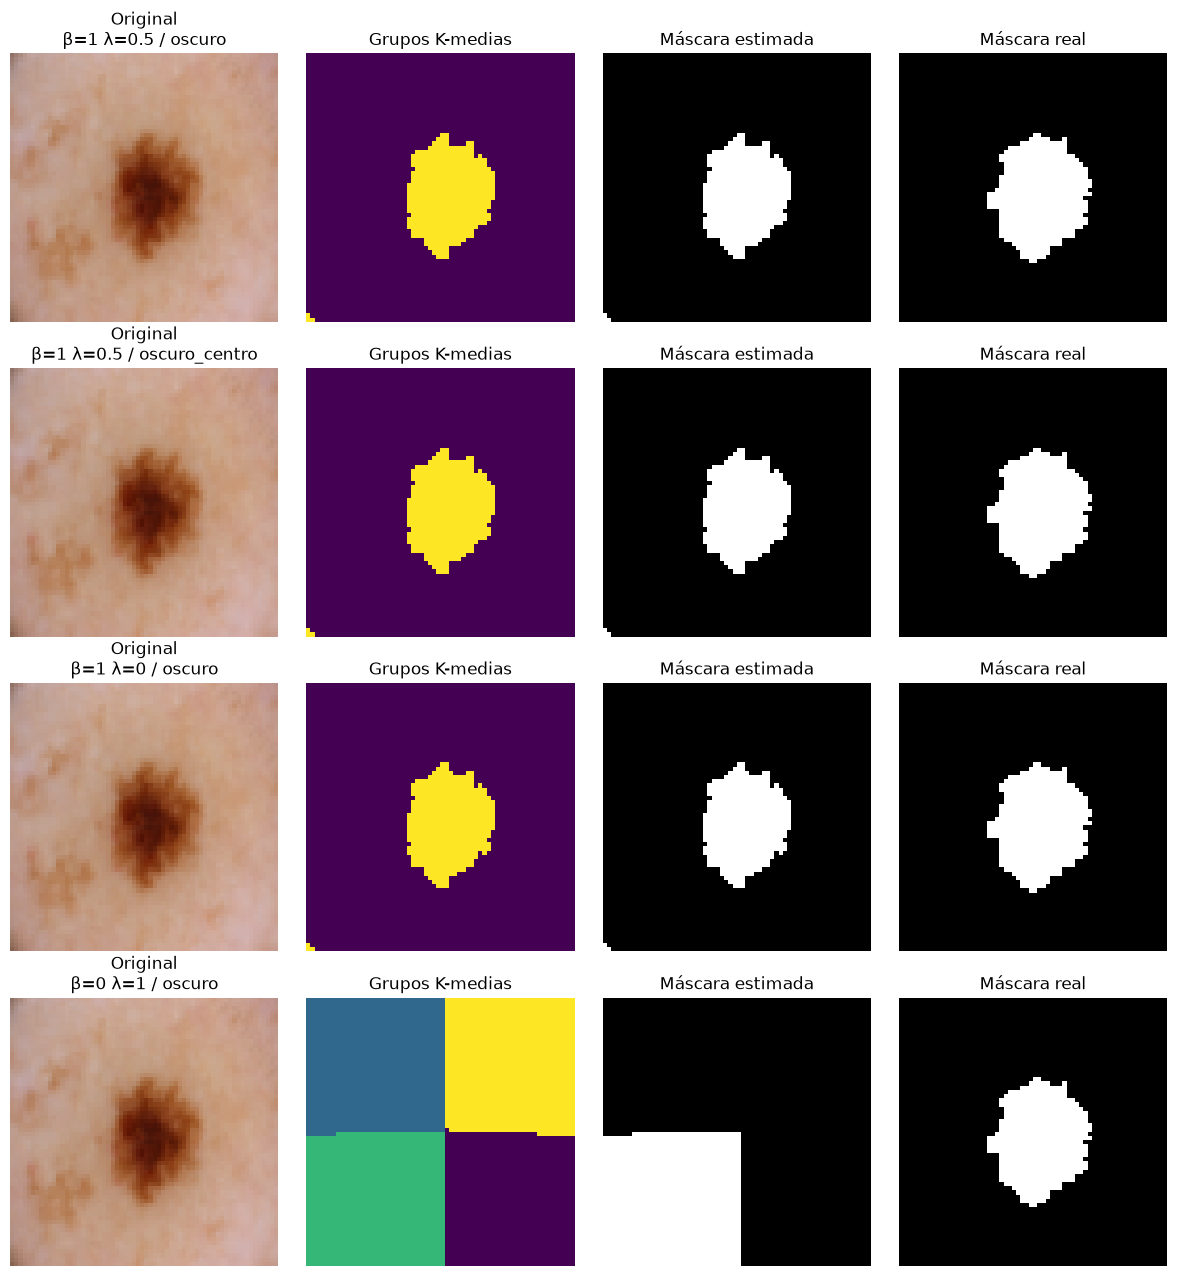

In [22]:
mejor=resumen.iloc[0]
BETA_FINAL=float(mejor['beta']);LAMBDA_FINAL=float(mejor['lambda'])
CRITERIO_FINAL=str(mejor['criterio'])
print('CONFIGURACIÓN FINAL CONGELADA')
print('beta:',BETA_FINAL,'lambda:',LAMBDA_FINAL,'criterio:',CRITERIO_FINAL)
print('Dice medio en ajuste:',round(float(mejor['Dice_promedio']),3))

# Un ejemplo de ajuste para las dos mejores configuraciones y las alternativas extremas.
seleccion=[tuple(x) for x in resumen[['beta','lambda','criterio']].head(2).itertuples(index=False,name=None)]
for b,l in [(1.,0.),(0.,1.)]:
    cr=(resumen[(resumen.beta==b)&(resumen['lambda']==l)].iloc[0]['criterio'])
    op=(b,l,str(cr))
    if op not in seleccion:seleccion.append(op)

ejemplo=AJUSTE[0];img,ref=DATOS[ejemplo]
fig,axes=plt.subplots(len(seleccion),4,figsize=(12,3.2*len(seleccion)))
for row,(b,l,cr) in enumerate(seleccion):
    res=CACHE_AJUSTE[(ejemplo,b,l)]
    mask=mascara_desde_grupos(img,res['labels'],cr)
    for col,arr,t in [(0,img,'Original'),(1,res['labels'],'Grupos K-medias'),
                       (2,mask,'Máscara estimada'),(3,ref,'Máscara real')]:
        axes[row,col].imshow(arr,cmap='gray' if col>=2 else None,
                             vmin=0 if col>=2 else None,vmax=1 if col>=2 else None)
        axes[row,col].set_title(f'{t}\nβ={b:g} λ={l:g} / {cr}' if col==0 else t)
        axes[row,col].axis('off')
plt.tight_layout();plt.show()

### Conclusiones preliminares: resultados de ajuste

Al comparar las 15 imágenes de ajuste, la mejor configuración obtuvo un **Dice promedio de 0.867**, usando **β = 1.0**, **λ = 0.5** y la regla **`oscuro`**. Esto significa que, en promedio, las máscaras calculadas se parecen bastante a las que marcaron los especialistas. No significa que el modelo acierte siempre: es una medida de coincidencia sobre las imágenes de ajuste.

- **El color y la posición juntos funcionaron mejor.** Usando solo color se obtuvo un Dice promedio de **0.856**, mientras que al sumar un peso moderado para la posición subió a **0.867**. La mejora fue pequeña, pero favoreció la combinación de ambas características.
- **La posición sola no fue suficiente.** Con β = 0 y λ = 1 el Dice promedio cayó a **0.313**. En la comparación visual, el modelo dividió la imagen en regiones según su ubicación en vez de reconocer el contorno de la lesión.
- **Las dos reglas automáticas quedaron empatadas en el promedio mostrado.** Las reglas `oscuro` y `oscuro_centro` obtuvieron **0.867** en la mejor combinación. La configuración congelada utiliza `oscuro`.
- **No todas las lesiones tienen la misma dificultad.** En la configuración ganadora, el Dice mínimo de ajuste fue **0.745**. Esto demuestra que hay imágenes en las que la máscara estimada todavía deja diferencias frente a la referencia.

Estas conclusiones se basan **solo en ajuste**. El comportamiento en las cinco imágenes de prueba se analiza más adelante, sin volver a elegir los parámetros.

### ¿Por qué esta configuración fue la elegida?

En las **15 imágenes de ajuste**, la mejor combinación fue **β = 1, λ = 0.5 y regla `oscuro`**. Tuvo un **Dice promedio de 0.867**. Este número va de 0 a 1 y resume cuánto se superpone la lesión encontrada con la marcada por los especialistas: cuanto más cerca esté de 1, mejor.

La comparación ayuda a entender la decisión:

| Características utilizadas | β | λ | Dice promedio en ajuste |
|---|---:|---:|---:|
| Color y posición | 1 | 0.5 | **0.867** |
| Solo color | 1 | 0 | 0.856 |
| Solo posición | 0 | 1 | 0.313 |

La posición aportó una mejora de **0.011 puntos de Dice** frente al color solo. No es una diferencia enorme, pero el promedio fue mejor. Al usar solamente la posición, el algoritmo separó zonas según dónde estaban los píxeles, sin reconocer la lesión. Esto también se ve en la última fila de las gráficas.

Las reglas `oscuro` y `oscuro_centro` quedaron empatadas en los resultados de la mejor combinación. Como no se observó una ventaja de usar la posición central para elegir el grupo, se dejó `oscuro`, que es una regla más sencilla. Esto no significa que siempre vaya a funcionar: hay lesiones claras y fondos oscuros que pueden confundirla.

La **silueta** se usó para elegir K y **Dice** para comparar la máscara estimada con la real. No cumplen la misma función. Una agrupación puede separar bien los colores y aun así seleccionar la región equivocada como lesión.

## 9. Revisión de los casos más difíciles de ajuste

Ordenamos las 15 imágenes por Dice de menor a mayor para identificar dónde falla el método elegido. Comparamos la máscara estimada con la referencia, sin cambiar los parámetros ya seleccionados.

,imagen,K,silueta,Dice,V_measure,precision,recall
110,ISIC_0000114,4,0.369,0.745,0.137,0.622,0.930
130,ISIC_0000116,4,0.459,0.747,0.311,0.999,0.596
170,ISIC_0000133,2,0.417,0.750,0.441,0.697,0.812
290,ISIC_0000112,5,0.427,0.777,0.234,0.951,0.657
210,ISIC_0000150,2,0.472,0.823,0.576,0.999,0.700
270,ISIC_0000157,2,0.527,0.859,0.629,1.000,0.752
150,ISIC_0000122,5,0.473,0.890,0.382,1.000,0.801
230,ISIC_0000153,4,0.414,0.907,0.436,0.943,0.874
70,ISIC_0000094,5,0.402,0.913,0.209,0.869,0.963
250,ISIC_0000156,2,0.576,0.915,0.710,0.982,0.857


Peor ejemplo de ajuste: ISIC_0000114 | Dice = 0.745


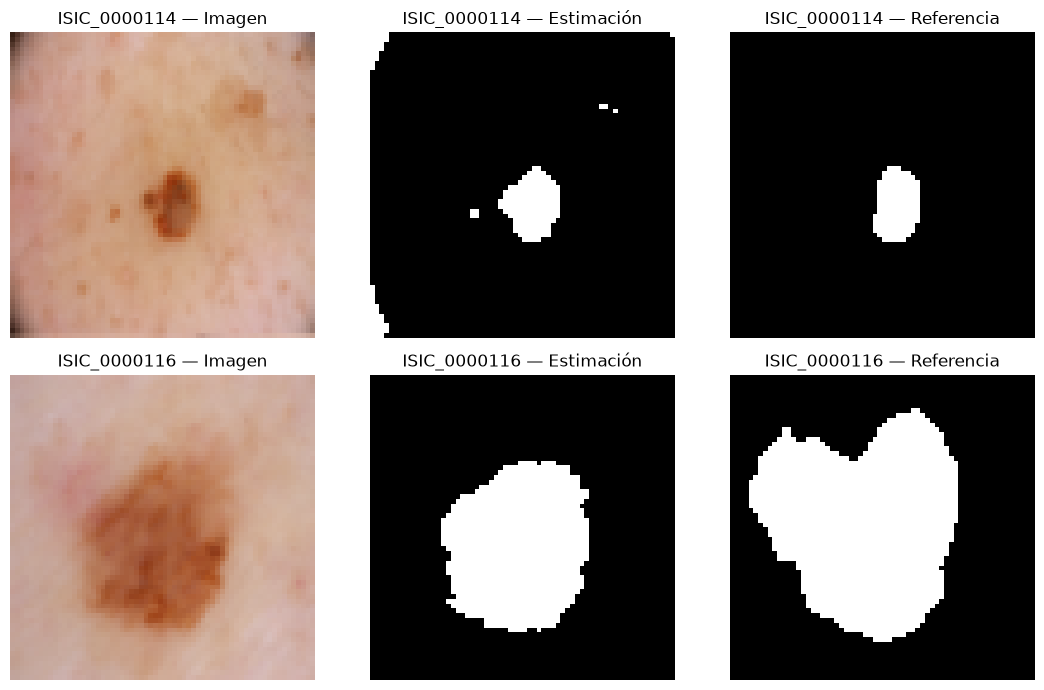

In [23]:
elegidos=df_ajuste[(df_ajuste.beta==BETA_FINAL)&(df_ajuste['lambda']==LAMBDA_FINAL)&
                    (df_ajuste.criterio==CRITERIO_FINAL)].sort_values('Dice')
display(elegidos[['imagen','K','silueta','Dice','V_measure','precision','recall']].round(3))
print('Peor ejemplo de ajuste:',elegidos.iloc[0].imagen,
      '| Dice =',round(elegidos.iloc[0].Dice,3))

fig,axes=plt.subplots(2,3,figsize=(11,7))
for row,ident in enumerate(elegidos.imagen.head(2)):
    img,ref=DATOS[ident];r=CACHE_AJUSTE[(ident,BETA_FINAL,LAMBDA_FINAL)]
    pred=mascara_desde_grupos(img,r['labels'],CRITERIO_FINAL)
    for j,(arr,t) in enumerate([(img,'Imagen'),(pred,'Estimación'),(ref,'Referencia')]):
        axes[row,j].imshow(arr,cmap='gray' if j else None,vmin=0 if j else None,vmax=1 if j else None)
        axes[row,j].set_title(f'{ident} — {t}');axes[row,j].axis('off')
plt.tight_layout();plt.show()

### ¿Qué nos enseñaron las imágenes difíciles de ajuste?

Con los parámetros elegidos, la imagen **ISIC_0000114** fue la de menor Dice en ajuste (**0.745**). Su **precisión fue 0.622** y su **recall 0.930**. Esto significa que recuperó gran parte de la lesión, pero también incluyó píxeles que no pertenecían a ella: el problema principal de esa imagen fueron los **falsos positivos**.

En **ISIC_0000116**, el Dice fue **0.747**, con precisión **0.999** y recall **0.596**. Aquí sucedió lo contrario: casi todos los píxeles que marcó como lesión eran correctos, pero dejó por fuera una parte importante de la lesión (**falsos negativos**).

Estos dos ejemplos muestran que un Dice parecido puede esconder errores distintos. Por eso no basta con reportar el promedio: también hay que revisar precisión, recall y máscaras. Las imágenes de esta sección sirven para revisar los casos con más dificultades, **sin cambiar los parámetros**.

## 10. Prueba final: evaluación una sola vez

**A partir de aquí NO se modifican β, λ ni el criterio.** Para cada imagen nueva seguimos el mismo proceso: escoger K por silueta, asignar grupos, crear la máscara y medir el resultado. Las referencias de prueba sirven **solamente para obtener las métricas finales**.

,imagen,K,silueta,Dice,V_measure,precision,recall
0,ISIC_0000087,2,0.510,0.881,0.639,0.997,0.790
1,ISIC_0000105,4,0.401,0.900,0.257,0.949,0.856
2,ISIC_0000110,6,0.425,0.000,0.180,0.000,0.000
3,ISIC_0000123,2,0.545,0.894,0.684,0.842,0.953
4,ISIC_0000128,2,0.556,0.933,0.818,1.000,0.874


Dice medio ajuste = 0.867
Dice medio prueba = 0.722
Diferencia prueba − ajuste = -0.145


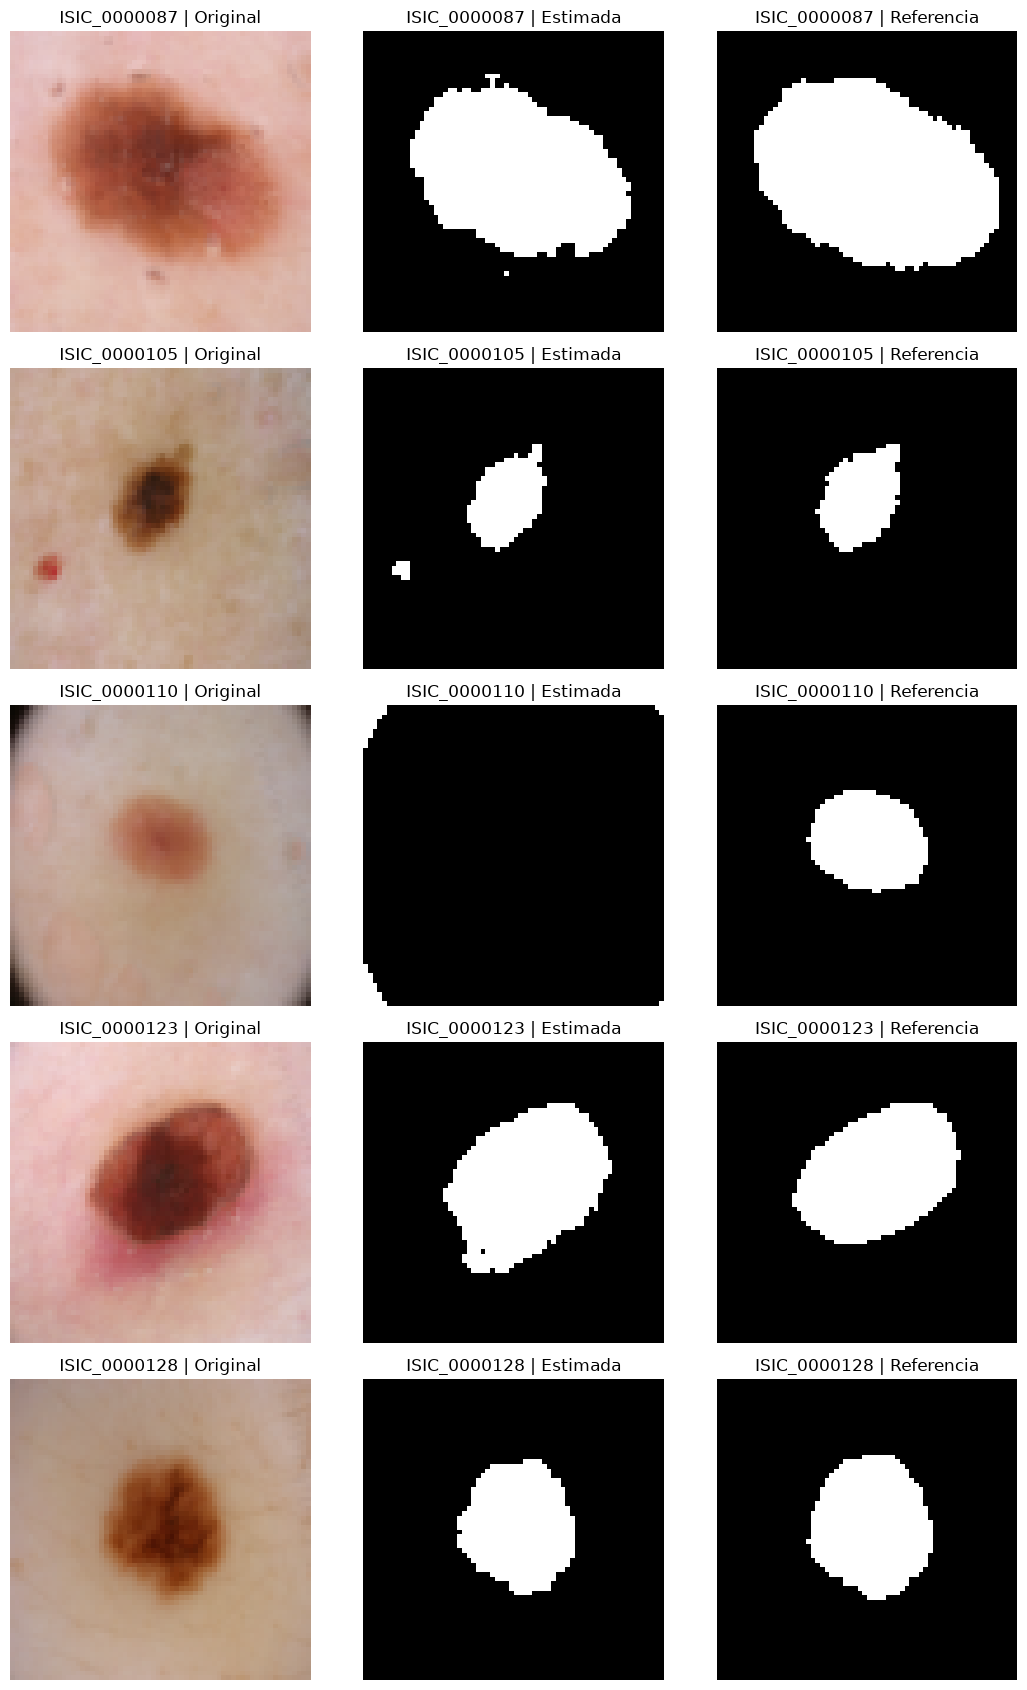

In [24]:
# Se ejecuta una sola vez después de haber congelado la configuración de ajuste.
filas_test=[]; TEST_PRED={}
for ident in PRUEBA:
    img,ref=DATOS[ident]
    r=agrupar(img,BETA_FINAL,LAMBDA_FINAL,ident)
    pred=mascara_desde_grupos(img,r['labels'],CRITERIO_FINAL)
    TEST_PRED[ident]=(r,pred)
    filas_test.append({'imagen':ident,'K':r['K'],'silueta':r['silueta'],
                       **metricas(ref,pred,r['labels'])})
df_prueba=pd.DataFrame(filas_test)
display(df_prueba.round(3))
print(f'Dice medio ajuste = {elegidos.Dice.mean():.3f}')
print(f'Dice medio prueba = {df_prueba.Dice.mean():.3f}')
print(f'Diferencia prueba − ajuste = {df_prueba.Dice.mean()-elegidos.Dice.mean():+.3f}')

fig,axes=plt.subplots(5,3,figsize=(11,17))
for row,ident in enumerate(PRUEBA):
    img,ref=DATOS[ident];r,pred=TEST_PRED[ident]
    for j,(arr,t) in enumerate([(img,'Original'),(pred,'Estimada'),(ref,'Referencia')]):
        axes[row,j].imshow(arr,cmap='gray' if j else None,vmin=0 if j else None,vmax=1 if j else None)
        axes[row,j].set_title(f'{ident} | {t}');axes[row,j].axis('off')
plt.tight_layout();plt.show()

### Lectura de los cinco resultados de prueba

Esta prueba se hizo con la configuración que ya estaba definida en ajuste: **β = 1, λ = 0.5 y `oscuro`**. No se utilizaron las máscaras de prueba para escoger los parámetros.

| Imagen | Dice | ¿Qué se observa en la comparación? |
|---|---:|---|
| ISIC_0000087 | 0.881 | La lesión se reconoce, pero la máscara estimada deja parte del contorno por fuera. Su recall fue 0.790. |
| ISIC_0000105 | 0.900 | La región principal se encuentra bastante bien, aunque también aparece una pequeña zona blanca separada que no pertenece a la lesión principal. |
| ISIC_0000110 | **0.000** | **Fallo completo:** la máscara estimada selecciona casi todo el fondo, mientras que la máscara real marca una lesión redondeada en el centro. |
| ISIC_0000123 | 0.894 | La forma general coincide; la máscara estimada es algo más amplia en algunas partes. |
| ISIC_0000128 | **0.933** | Es el mejor resultado de prueba: la forma y la ubicación de ambas máscaras se parecen bastante. |

La **imagen ISIC_0000110** es la más importante para explicar las limitaciones. En la fotografía la lesión central es más clara que otras lesiones del conjunto, y aparecen regiones oscuras en las esquinas. El criterio `oscuro` puede confundirse porque **ser oscuro no es lo mismo que ser una lesión**. La máscara calculada muestra que escogió casi todo el fondo en lugar de la región central; por eso tanto la precisión como el recall fueron **0.000**. Esta explicación se basa en la comparación visual de esa fotografía y las máscaras, no en un diagnóstico médico.

El Dice promedio pasó de **0.867 en ajuste** a **0.722 en prueba**: una diferencia de **−0.145**. La caída no significa que el algoritmo falle siempre, ya que cuatro imágenes de prueba obtuvieron Dice mayor que **0.88**. Sin embargo, un solo fallo grave perjudicó el promedio y muestra que el comportamiento no es igual en todas las fotografías.

## 11. Análisis de resultados — cinco preguntas de la guía

**Estas respuestas se construyen con cifras obtenidas en la ejecución.** Se complementan con explicaciones sencillas de qué significa cada resultado. Ningún valor de prueba se usa para redefinir la configuración.

In [26]:
# 12.1 ¿Qué cambia al incluir la posición?
col=df_ajuste[(df_ajuste.beta==1)&(df_ajuste['lambda']==0)&(df_ajuste.criterio==CRITERIO_FINAL)]
mez=df_ajuste[(df_ajuste.beta==BETA_FINAL)&(df_ajuste['lambda']==LAMBDA_FINAL)&(df_ajuste.criterio==CRITERIO_FINAL)]
comparacion=col[['imagen','Dice']].merge(mez[['imagen','Dice']],on='imagen',suffixes=('_solo_color','_color_posicion'))
comparacion['diferencia']=comparacion.Dice_color_posicion-comparacion.Dice_solo_color
print('PREGUNTA 1 — EFECTO DE LA POSICIÓN')
display(comparacion.sort_values('diferencia',ascending=False).round(3))
print('Mejora en',int((comparacion.diferencia>0).sum()),'de 15 imágenes; empeora en',int((comparacion.diferencia<0).sum()),'y empata en',int((comparacion.diferencia==0).sum()),'.')
print('Mayor mejora:',comparacion.loc[comparacion.diferencia.idxmax(),'imagen'],'| diferencia:',round(comparacion.diferencia.max(),3))
print('Mayor deterioro:',comparacion.loc[comparacion.diferencia.idxmin(),'imagen'],'| diferencia:',round(comparacion.diferencia.min(),3))
print('Interpretación: la posición puede ayudar a mantener regiones cercanas en el mismo grupo; también puede separar partes de la lesión o confundir una lesión descentrada.')

print('\nPREGUNTA 2 — K, SILUETA Y DICE')
cor=df_ajuste[['K','silueta','Dice']].corr(numeric_only=True)
display(cor.round(3))
print('K promedio de la mejor configuración:',round(float(elegidos.K.mean()),2))
print('Silueta evalúa separación de grupos sin ver la máscara; Dice evalúa coincidencia con la lesión. Por eso el K de mayor silueta no garantiza mayor Dice.')

print('\nPREGUNTA 3 — AJUSTE Y PRUEBA')
print(f'Ajuste: {elegidos.Dice.mean():.3f}; prueba: {df_prueba.Dice.mean():.3f}; cambio: {df_prueba.Dice.mean()-elegidos.Dice.mean():+.3f}.')
print('La prueba es una estimación fuera de ajuste. Cambiar los parámetros después de verla contaminaría esa evaluación y produciría un resultado demasiado optimista.')

print('\nPREGUNTA 4 — DOS LIMITACIONES')
print('1) RGB no entiende anatomía: una sombra, vello o reflejo puede compartir color con la lesión. En las peores imágenes, contraste máscaras y revise esta causa.')
print('2) La ubicación es una aproximación: si la lesión está fuera del centro o es irregular, una regla espacial puede perder partes. Revise los ejemplos de Dice bajo.')

print('\nPREGUNTA 5 — RIESGOS EN DERMALPES')
print('Falso positivo: marcar piel sana como lesión puede distorsionar el área y hacer perder tiempo al especialista.')
print('Falso negativo: dejar parte de una lesión fuera puede subestimar su tamaño o su contorno, un problema potencialmente más delicado.')
print('Generalización: tonos de piel, iluminación, tipo de dermatoscopio, compresión, vello y lesiones diferentes pueden cambiar colores y patrones.')
print('Uso responsable: mostrar incertidumbre, verificar con profesionales y evaluar diversidad de imágenes antes de cualquier aplicación clínica. No utilizar para diagnóstico autónomo.')

PREGUNTA 1 — EFECTO DE LA POSICIÓN


,imagen,Dice_solo_color,Dice_color_posicion,diferencia
5,ISIC_0000114,0.593,0.745,0.152
3,ISIC_0000094,0.873,0.913,0.040
14,ISIC_0000112,0.745,0.777,0.031
0,ISIC_0000085,0.920,0.922,0.002
9,ISIC_0000137,0.945,0.946,0.002
1,ISIC_0000086,0.936,0.937,0.001
4,ISIC_0000108,0.921,0.922,0.001
2,ISIC_0000089,0.948,0.948,0.000
12,ISIC_0000156,0.915,0.915,0.000
8,ISIC_0000133,0.751,0.750,-0.000


Mejora en 7 de 15 imágenes; empeora en 6 y empata en 2 .
Mayor mejora: ISIC_0000114 | diferencia: 0.152
Mayor deterioro: ISIC_0000153 | diferencia: -0.029
Interpretación: la posición puede ayudar a mantener regiones cercanas en el mismo grupo; también puede separar partes de la lesión o confundir una lesión descentrada.

PREGUNTA 2 — K, SILUETA Y DICE


,K,silueta,Dice
K,1.000,-0.776,-0.239
silueta,-0.776,1.000,0.419
Dice,-0.239,0.419,1.000


K promedio de la mejor configuración: 3.0
Silueta evalúa separación de grupos sin ver la máscara; Dice evalúa coincidencia con la lesión. Por eso el K de mayor silueta no garantiza mayor Dice.

PREGUNTA 3 — AJUSTE Y PRUEBA
Ajuste: 0.867; prueba: 0.722; cambio: -0.145.
La prueba es una estimación fuera de ajuste. Cambiar los parámetros después de verla contaminaría esa evaluación y produciría un resultado demasiado optimista.

PREGUNTA 4 — DOS LIMITACIONES
1) RGB no entiende anatomía: una sombra, vello o reflejo puede compartir color con la lesión. En las peores imágenes, contraste máscaras y revise esta causa.
2) La ubicación es una aproximación: si la lesión está fuera del centro o es irregular, una regla espacial puede perder partes. Revise los ejemplos de Dice bajo.

PREGUNTA 5 — RIESGOS EN DERMALPES
Falso positivo: marcar piel sana como lesión puede distorsionar el área y hacer perder tiempo al especialista.
Falso negativo: dejar parte de una lesión fuera puede subestimar su tamaño

### Respuestas explicadas a las cinco preguntas de análisis

**1. ¿Qué cambió al incluir la posición de los píxeles?**

La posición ayudó en algunos casos, pero no en todos. El ejemplo más claro es **ISIC_0000114**: con solo color tuvo Dice de **0.593** y al añadir posición subió a **0.745**, es decir, mejoró **0.152**. En cambio, **ISIC_0000153** pasó de **0.936** con solo color a **0.907** con color y posición, una disminución de **0.029**. En general, la posición favorece grupos de píxeles cercanos, pero también puede separar una lesión que tiene formas o colores variados. En la comparación registrada, la posición mejoró 7 imágenes, empeoró 6 y empató en 2, usando los valores sin redondear.

**2. ¿Cómo se relacionan K, la silueta y el Dice?**

**K** indica en cuántos grupos se dividen los píxeles. La **silueta** mide si esos grupos están bien separados usando las características de color y posición; por eso sirve para elegir K sin consultar la máscara real. **Dice** mide algo diferente: si la máscara de lesión construida con los grupos coincide con la referencia. En la configuración seleccionada el **K promedio fue 3**, pero esto no significa que K=3 sea siempre el mejor para todas las imágenes. La imagen de prueba **ISIC_0000110** tuvo **K=6**, silueta **0.425** y Dice **0.000**. Es una demostración concreta de que una silueta positiva no garantiza que se encuentre la lesión correcta.

**3. ¿Cómo se compararon ajuste y prueba?**

El Dice promedio de ajuste fue **0.867** y el de prueba **0.722**, una disminución de **0.145**. Es importante reservar imágenes para prueba porque, si se cambian β, λ o la regla después de ver sus resultados, esas imágenes ya estarían ayudando a escoger el método. En ese caso, la evaluación dejaría de ser una comprobación independiente. Además, el conjunto de prueba tiene solo cinco imágenes, así que el promedio puede cambiar mucho con un solo caso difícil.

**4. ¿Cuáles son dos limitaciones del método?**

La primera limitación es **confundir zonas oscuras con lesiones**. El algoritmo usa números RGB, pero no entiende qué parte de la imagen es piel ni qué parte es una lesión. En **ISIC_0000110** seleccionó casi todo el fondo en lugar de la lesión, lo que produjo Dice **0.000**. La segunda limitación es **no capturar siempre todo el contorno**: en **ISIC_0000087** el recall fue **0.790**, lo cual indica que parte de la lesión real quedó por fuera. La reducción a 64 × 64 píxeles también simplifica los bordes y puede perder detalles finos. Estas dificultades provienen de usar solamente color y posición para decidir.

**5. ¿Qué riesgos tendría utilizar este resultado en DermAlpes?**

Un **falso positivo** marca piel sana como lesión y puede hacer que su tamaño parezca mayor. Un **falso negativo** deja parte de la lesión por fuera y puede hacer que su tamaño parezca menor. En telemedicina esto puede afectar las mediciones que revisa el especialista. Además, las fotografías de este laboratorio son pocas: el método podría cambiar su desempeño según la iluminación, el tono de piel, el equipo utilizado o la apariencia de la lesión. Antes de usarlo con pacientes reales habría que evaluarlo con fotografías más variadas y mantener siempre la revisión de un profesional. **El método delimita regiones; no diagnostica enfermedades.**

## Conclusiones finales

El experimento muestra que **K-medias puede servir como primera aproximación para delimitar lesiones**, pero no reemplaza la revisión de un especialista. El modelo identifica grupos de píxeles parecidos; no comprende qué es una lesión ni realiza diagnósticos.

En las 15 imágenes de ajuste, la mejor combinación fue **β = 1, λ = 0.5, criterio `oscuro`**, con Dice promedio de **0.867**. Solo color logró **0.856** y solo posición **0.313**. Por tanto, incorporar la ubicación ayudó cuando se usó junto con el color, pero la ubicación sola no permite encontrar correctamente la lesión.

La comparación visual también muestra que el modelo puede aproximarse al contorno de ciertas lesiones, aunque a veces deja píxeles de la lesión sin seleccionar o marca piel como lesión. Esta es una limitación importante si se quiere medir el tamaño de una lesión.

**El resultado de prueba se completa automáticamente en la siguiente celda**, usando las cinco imágenes que se reservaron desde el inicio. No deben cambiarse los parámetros después de conocer esos valores.

In [27]:
dice_ajuste = float(elegidos.Dice.mean())
dice_prueba = float(df_prueba.Dice.mean())
peor = df_prueba.loc[df_prueba.Dice.idxmin()]
mejor_prueba = df_prueba.loc[df_prueba.Dice.idxmax()]

print('CONCLUSIONES CON LOS RESULTADOS DE PRUEBA')
print(f'1. En ajuste, el Dice promedio fue {dice_ajuste:.3f}; en prueba fue {dice_prueba:.3f}.')
if dice_prueba < dice_ajuste:
    print('   El desempeño bajó en imágenes nuevas. Esto muestra que los resultados de ajuste eran más favorables que los de prueba.')
elif dice_prueba > dice_ajuste:
    print('   El desempeño subió en estas cinco imágenes nuevas, aunque la muestra de prueba es pequeña.')
else:
    print('   El Dice promedio fue igual en ambos conjuntos.')
print(f'2. El mejor resultado de prueba fue {mejor_prueba.imagen}, con Dice {mejor_prueba.Dice:.3f}.')
print(f'3. El resultado más bajo fue {peor.imagen}, con Dice {peor.Dice:.3f}.')
print('4. El método no es perfecto: algunas zonas pueden quedar por fuera o incluir piel sana.')
print('5. Para usarlo con pacientes reales habría que probarlo con más imágenes y condiciones diferentes, siempre con revisión profesional.')

CONCLUSIONES CON LOS RESULTADOS DE PRUEBA
1. En ajuste, el Dice promedio fue 0.867; en prueba fue 0.722.
   El desempeño bajó en imágenes nuevas. Esto muestra que los resultados de ajuste eran más favorables que los de prueba.
2. El mejor resultado de prueba fue ISIC_0000128, con Dice 0.933.
3. El resultado más bajo fue ISIC_0000110, con Dice 0.000.
4. El método no es perfecto: algunas zonas pueden quedar por fuera o incluir piel sana.
5. Para usarlo con pacientes reales habría que probarlo con más imágenes y condiciones diferentes, siempre con revisión profesional.


### Conclusiones generales del laboratorio

**1. El método puede encontrar la lesión en varias imágenes.** La mejor configuración obtuvo un Dice promedio de **0.867** en ajuste. En prueba, cuatro de las cinco imágenes lograron un Dice superior a **0.88**. Esto demuestra que agrupar píxeles por color y posición puede servir como un primer intento de segmentación.

**2. Usar color es mucho más útil que usar solamente la ubicación.** En ajuste, solo color consiguió **0.856**, mientras que solo posición obtuvo **0.313**. Combinar color y posición con un peso moderado mejoró ligeramente el promedio hasta **0.867**.

**3. No hay una configuración que funcione igual de bien en todos los casos.** En prueba, la imagen **ISIC_0000128** consiguió Dice **0.933**, mientras que **ISIC_0000110** obtuvo **0.000**. El algoritmo no entiende el significado de la lesión y puede seleccionar el fondo por error.

**4. La precisión y el recall son necesarios para comprender los errores.** En ajuste, **ISIC_0000114** recuperó gran parte de la lesión, pero incluyó demasiada piel sana (precisión **0.622**, recall **0.930**). En **ISIC_0000116** seleccionó pocos píxeles incorrectos, pero dejó sin marcar parte de la lesión (precisión **0.999**, recall **0.596**). Aunque ambos Dice se parecen, los tipos de error son distintos.

**5. El resultado de prueba es más exigente que el de ajuste.** El Dice medio bajó de **0.867** a **0.722**. Por eso es necesario separar las imágenes usadas para elegir parámetros de las usadas para evaluar el resultado final. Tampoco conviene afirmar que el método funcionará de la misma forma con pacientes nuevos: se evaluaron únicamente cinco imágenes de prueba.

**6. La herramienta necesita supervisión.** Puede apoyar a un dermatólogo al proponer un contorno inicial, pero no se debería usar para tomar decisiones clínicas por sí sola. Se necesita revisar cada máscara, especialmente en fotografías con poco contraste, sombras o lesiones de apariencia diferente.

**Conclusión final:** el objetivo del laboratorio no era obtener un resultado perfecto, sino construir una segmentación reproducible, medir sus aciertos y reconocer cuándo falla. Los resultados muestran que K-medias es una aproximación útil en algunas fotografías, pero no suficientemente confiable por sí sola para una aplicación clínica.

## 12. Bono

### Bono A. Visualización con PCA

PCA representa las cinco características en dos dimensiones para facilitar su inspección. Los colores de la primera figura indican el grupo predicho y los de la segunda indican la máscara experta. **Una proyección 2D pierde información**; no demuestra por sí sola una segmentación buena.

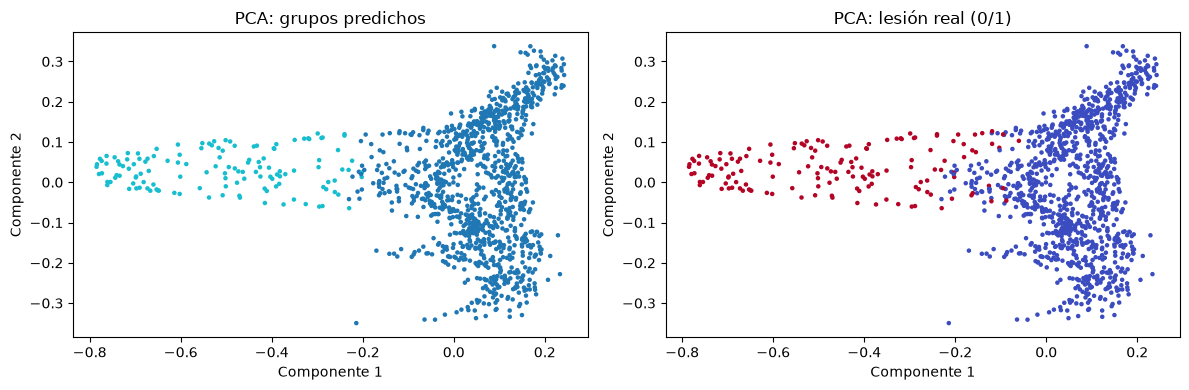

In [29]:
ident=AJUSTE[0]
img,ref=DATOS[ident]
r=CACHE_AJUSTE[(ident,BETA_FINAL,LAMBDA_FINAL)]
X=pipeline(BETA_FINAL,LAMBDA_FINAL).fit_transform(img)
idx=np.random.default_rng(SEED).choice(len(X),size=min(1200,len(X)),replace=False)
coords=PCA(n_components=2,random_state=SEED).fit_transform(X[idx])
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].scatter(coords[:,0],coords[:,1],c=r['labels'].ravel()[idx],s=5,cmap='tab10')
ax[0].set_title('PCA: grupos predichos')
ax[1].scatter(coords[:,0],coords[:,1],c=ref.ravel()[idx],s=5,cmap='coolwarm')
ax[1].set_title('PCA: lesión real (0/1)')
for a in ax:a.set_xlabel('Componente 1');a.set_ylabel('Componente 2')
plt.tight_layout();plt.show()

### Análisis de los resultados de PCA

En este bono utilizamos PCA para representar los píxeles de una imagen en dos dimensiones. Originalmente, cada píxel tiene cinco características relacionadas con su color y su posición. PCA permite reducir estas características a dos componentes para facilitar su visualización.

En la primera gráfica, los puntos están coloreados según los grupos obtenidos mediante K-medias. En la segunda gráfica, los puntos están coloreados según la máscara de referencia, que diferencia la lesión del fondo.

Al comparar ambas gráficas, podemos observar que existe cierta relación entre los grupos formados por K-medias y las regiones identificadas en la máscara de referencia. Esto muestra que las características de color y posición permiten distinguir algunos píxeles de la lesión de los que pertenecen al fondo.

Sin embargo, los grupos de K-medias no necesariamente coinciden por completo con la máscara real. Esto ocurre porque K-medias agrupa píxeles que tienen características similares, pero no sabe cuáles pertenecen realmente a una lesión. Por esta razón, algunos píxeles del fondo pueden quedar agrupados con los de la lesión, o una misma lesión puede dividirse en varios grupos.

También debemos tener en cuenta que PCA reduce cinco características a solamente dos dimensiones. Aunque esto facilita observar los datos, se puede perder parte de la información original. Por lo tanto, dos grupos que parecen estar mezclados en la gráfica podrían estar mejor separados cuando se consideran las cinco características completas.

En conclusión, PCA nos permitió visualizar cómo se distribuyen los píxeles y comparar los grupos de K-medias con la máscara real. Sin embargo, estas gráficas no son suficientes para determinar si la segmentación es correcta. Por eso, también necesitamos utilizar métricas como Dice y V-measure para evaluar los resultados.

## Uso de herramientas de IA generativa

### 1. Herramienta utilizada

Durante el desarrollo de este laboratorio utilizamos **ChatGPT, de OpenAI**, como herramienta de apoyo para comprender algunos conceptos, revisar el código y mejorar las explicaciones de los resultados.

La herramienta nos ayudó principalmente a entender cómo aplicar K-medias para segmentar imágenes, cómo interpretar las métricas de evaluación y cómo identificar posibles errores en las máscaras obtenidas.

### Conclusión sobre el uso de IA generativa

Consideramos que ChatGPT fue una herramienta útil para apoyar el desarrollo del laboratorio, especialmente en la comprensión de conceptos, la identificación de errores y la interpretación de resultados.

Sin embargo, sus recomendaciones no reemplazan la necesidad de realizar experimentos. Aunque la configuración inicial obtuvo un Dice promedio de 0.825, encontramos una alternativa con un mejor resultado de 0.867 al comparar las configuraciones de manera sistemática.

### Evidencia de las interacciones

- ¿Me puedes explicar de manera más sencilla por qué es importante utilizar tanto el color como la posición de los píxeles?

- Quiero entender qué podría pasar si utilizo solamente el color o solamente la posición y por qué el valor de K puede cambiar los resultados de la segmentación.

- ¿Me puedes explicar qué significa este resultado y qué puedo concluir a partir de él?

- ¿Me puedes explicar cuál es la diferencia entre estas métricas? ¿Por qué puedo obtener un V-measure relativamente bueno y al mismo tiempo un Dice bajo?

- ¿Por qué pudo disminuir el desempeño del método? ¿Qué me dice esta diferencia sobre su capacidad para funcionar con imágenes nuevas?
